# 03. Statistical validation against USGS rupture mapping

**Step 4 of 4:** ASF search & download → SNAP coherence processing → Python differencing → **Statistical validation**

**Follows notebook 02.** Notebook 02 maps Δγ and compares it visually with the USGS traces. This notebook tests the match with three questions:

1. **Q1. Distance decay:** is coherence loss concentrated around the mapped USGS rupture, and if so over what distance?
   - The width of the near-rupture peak is used as the tolerance distance (**w**) for Q2 and Q3.
2. **Q2. Concentration:** within **w**, how much of the mapped USGS rupture is covered by coherence loss?
3. **Q3. Correctness:** what fraction of detected pixels lies within **w** of a mapped rupture?
   - This is a lower bound: the USGS mapping may have missed some ruptures that the imaging still picks up, and those detections count as errors here.

Each answer is compared against copies of the rupture lines shifted 3–7 km away in 12 directions. If the real lines score higher than every shifted copy, the result is unlikely to be due to chance.

The functions are in `src/ccd_utils.py`.

In [1]:
# may not need to run this - I was having environment issues with GDAL
import os, sys
from pathlib import Path

if os.name == "nt":
    env = Path(sys.prefix)
    os.environ["PATH"] = str(env / "Library" / "bin") + os.pathsep + os.environ["PATH"]
    os.environ.setdefault("GDAL_DATA", str(env / "Library" / "share" / "gdal"))
    os.environ.setdefault("PROJ_DATA", str(env / "Library" / "share" / "proj"))
    os.environ.setdefault("PROJ_LIB",  str(env / "Library" / "share" / "proj"))

In [ ]:
import os, sys
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "src"))
import ccd_utils as ccd

## 1. Configuration

In [3]:
DATA = REPO / "data"
PRE_COH = DATA / "processed" / "PreEventCoherence.tif"
CO_COH  = DATA / "processed" / "PostEventCoherence.tif"
AOI_PATH = DATA / "aoi" / "AOI_Ridgecrest_CA.kml"
RUPTURE_PATH = DATA / "usgs" / "USGS_rupturetrace_v4.kml"

COH_BAND = None        # None = auto-detect the 'coh' band
CRS = ccd.DEFAULT_CRS  # UTM 11N, metres
RESOLUTION = 10        # m

# Validation settings
RUPTURE_SOURCE = None           # None = all traces; "pontietal" = field-mapped traces only (drops PixelTracking)
W_M = None                      # tolerance (m); None = half-width of the near-rupture peak (section 3)
SHIFTS_M = (3000, 5000, 7000)   # shifted-line distances (m)
N_DIRECTIONS = 12               # directions per distance; copies pushed mostly off the data are skipped

OUT_DIR = DATA / "processed"
FIG_DIR = REPO / "figures"
FIG_DIR.mkdir(exist_ok=True)

## 2. Rebuild Δγ on the notebook 02 grid

We repeat the gridding and differencing from notebook 02 so this notebook runs on its own. Before thresholding we median-filter Δγ (`ccd.smooth`, 5 × 5). Without this, an isolated noise pixel near a trace would count up to 2*w* of rupture as detected.

In [4]:
aoi = ccd.load_aoi(AOI_PATH)
transform, shape, crs = ccd.common_grid(aoi, crs=CRS, resolution=RESOLUTION)
coh_pre = ccd.mask_outside(ccd.to_grid(PRE_COH, transform, shape, crs, band=COH_BAND), aoi, transform, crs)
coh_co  = ccd.mask_outside(ccd.to_grid(CO_COH,  transform, shape, crs, band=COH_BAND), aoi, transform, crs)
diff = ccd.coherence_difference(coh_pre, coh_co)
diff_s = ccd.smooth(diff, size=5)

rupture = gpd.read_file(RUPTURE_PATH).to_crs(crs)
if RUPTURE_SOURCE:
    rupture = rupture[rupture["Source"].str.lower() == RUPTURE_SOURCE.lower()]

dist = ccd.distance_to_lines(rupture, transform, shape, crs)
points = ccd.sample_lines(rupture, crs, step=5.0)          # one point per 5 m of rupture
on_data = ccd._at_points(np.isfinite(diff), points, transform) == 1

print(f"Grid {shape[1]} x {shape[0]} px, {np.isfinite(diff).mean():.0%} valid")
print(f"Rupture: {len(rupture)} features, {len(points) * 5 / 1e3:.1f} km, "
      f"{on_data.sum() * 5 / 1e3:.1f} km on valid data (the rest is outside the swath)")

Grid 4552 x 5574 px, 82% valid
Rupture: 196 features, 160.2 km, 109.4 km on valid data (the rest is outside the swath)


## 3. Distance decay (Q1) and the tolerance *w*

The background level is the median Δγ more than 3 km from any trace. The profile has two parts, and each gives a distance:

* **Peak half-width → *w*:** where the excess over background falls to 50% of its peak. This is the sharp drop next to the traces, the rupture itself as seen through the ~40 m coherence window.
* **Tail width → Q1 finding:** where the excess falls to 10% of its peak. This is the zone of distributed cracking and shaking damage around the rupture. It is reported as a result, not used as a tolerance. Using it as *w* would make almost any line count as "detected" and leave too little room for the shifted-line test.

In [5]:
profile = ccd.distance_profile(diff, dist, max_dist=3000, step=20)
background = np.nanmedian(diff[dist > 3000])
w_peak = ccd.decay_distance(diff, dist, profile, background_min=3000, fraction=0.5)
w_tail = ccd.decay_distance(diff, dist, profile, background_min=3000, fraction=0.1)
w = W_M if W_M is not None else w_peak
if not np.isfinite(w):
    raise ValueError("Δγ never falls to half its peak within 3 km; set W_M by hand.")
print(f"background Δγ = {background:.3f}")
print(f"peak half-width = {w_peak:.0f} m  -> using w = {w:.0f} m")
print(f"tail width (to 10% of peak) = {w_tail:.0f} m  -> zone of off-fault disruption")

background Δγ = -0.028
peak half-width = 230 m  -> using w = 230 m
tail width (to 10% of peak) = 2150 m  -> zone of off-fault disruption


## 4. Concentration and correctness across thresholds (Q2, Q3)
*Wiedemann, Heipke, Mayer & Jamet (1998), “Empirical Evaluation of Automatically Extracted Road Axes.”*

**Concentration (Q2)** is the fraction of the reference data (USGS rupture) that lies within the buffer *w* around the extracted data (detected pixels). Wiedemann et al. call this *completeness*, which is the name used in `ccd_utils`.
**Correctness (Q3)** is the fraction of the extracted data that lies within the buffer *w* around the reference data.

The operating threshold is the one with the best harmonic mean of the two scores. Correctness is a lower bound, so this choice leans conservative.

In [6]:
thresholds = np.round(np.arange(0.05, 0.91, 0.025), 3)
sweep = ccd.threshold_sweep(diff_s, dist, points, transform, w, thresholds)

f1 = 2 * sweep.completeness * sweep.correctness / (sweep.completeness + sweep.correctness)
threshold = float(sweep.threshold[f1.idxmax()])
print(f"curve area = {sweep.attrs['area']:.2f}, operating threshold Δγ > {threshold}")
sweep[["threshold", "completeness", "correctness", "enrichment", "detected_pct_of_area"]].round(3)

curve area = 0.30, operating threshold Δγ > 0.475


,threshold,completeness,correctness,enrichment,detected_pct_of_area
0,0.050,1.000,0.086,3.443,22.677
1,0.075,1.000,0.104,4.179,17.703
2,0.100,1.000,0.122,4.910,14.218
3,0.125,1.000,0.139,5.608,11.688
4,0.150,1.000,0.156,6.270,9.757
5,0.175,0.994,0.172,6.908,8.235
6,0.200,0.994,0.186,7.480,7.004
7,0.225,0.989,0.199,7.991,5.980
8,0.250,0.988,0.210,8.464,5.100
9,0.275,0.986,0.221,8.873,4.346


## 5. Shifted-line test

We move the whole rupture map 3, 5 and 7 km in 12 directions and score each copy the same way as the real lines (Harms et al., 2001). Copies that would leave less than half of the line length on valid data are skipped. Pixels within 2*w* of the real rupture are masked, so no copy is scored on the real signal. With *n* copies, the smallest possible p-value is 1/(*n* + 1) (Phipson & Smyth, 2010).

In [7]:
obs, null, p = ccd.shifted_null(diff_s, rupture, transform, crs, threshold, w, shifts_m=SHIFTS_M,
                               n_directions=N_DIRECTIONS)

keys = ["near_excess", "completeness", "correctness"]
results = pd.DataFrame({
    "mapped rupture": [obs[k] for k in keys],
    "shifted lines (median)": [null[k].median() for k in keys],
    "p": [p[k] for k in keys],
}, index=["Q1 near-field excess Δγ", "Q2 concentration", "Q3 correctness (lower bound)"])
results.loc["enrichment (× chance)"] = [obs["enrichment"], null["enrichment"].median(), np.nan]
results.to_csv(OUT_DIR / "validation_results.csv")
print(f"w = {w:.0f} m, threshold Δγ > {threshold}, {len(null)} shifted copies "
      f"(smallest possible p = {1 / (len(null) + 1):.3f})")
results.round(3)

w = 230 m, threshold Δγ > 0.475, 33 shifted copies (smallest possible p = 0.029)


,mapped rupture,shifted lines (median),p
Q1 near-field excess Δγ,0.243,0.060,0.029
Q2 concentration,0.843,0.251,0.029
Q3 correctness (lower bound),0.259,0.035,0.029
enrichment (× chance),10.414,1.525,NaN


## 6. Summary figure

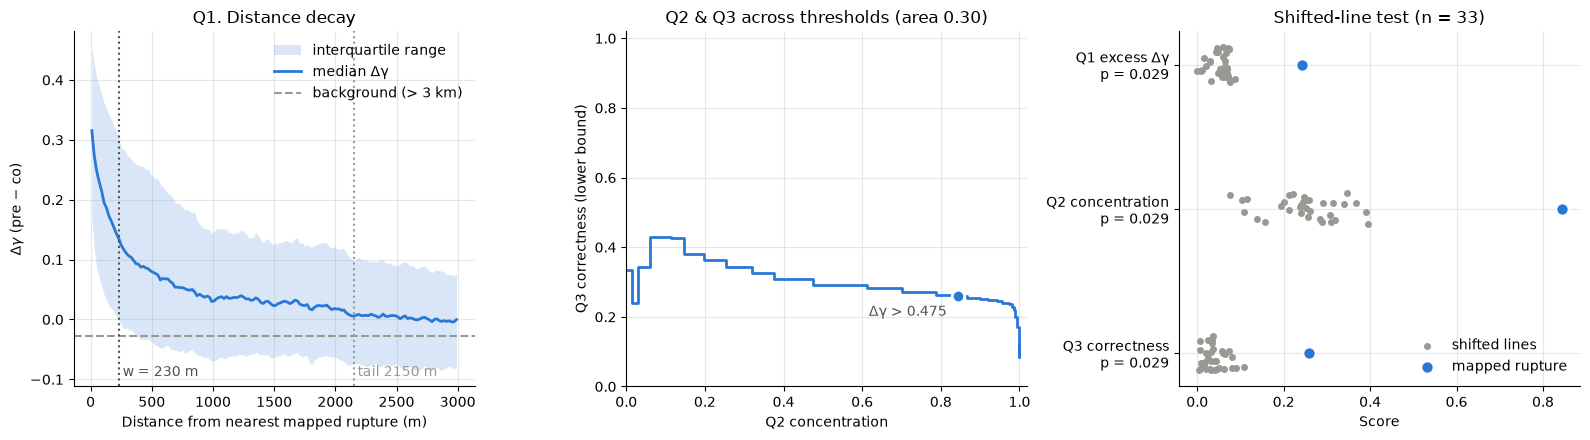

In [9]:
BLUE, GRAY, INK = "#2a78d6", "#9a9893", "#52514e"
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

a = ax[0]  # Q1
a.fill_between(profile.dist_m, profile.p25, profile.p75, color=BLUE, alpha=0.18, lw=0, label="interquartile range")
a.plot(profile.dist_m, profile["median"], color=BLUE, lw=2, label="median Δγ")
a.axhline(background, color=GRAY, ls="--", label="background (> 3 km)")
a.axvline(w, color=INK, ls=":")
a.text(w, 0.02, f" w = {w:.0f} m", transform=a.get_xaxis_transform(), va="bottom", color=INK)
if np.isfinite(w_tail):
    a.axvline(w_tail, color=GRAY, ls=":")
    a.text(w_tail, 0.02, f" tail {w_tail:.0f} m", transform=a.get_xaxis_transform(), va="bottom", color=GRAY)
a.set(xlabel="Distance from nearest mapped rupture (m)", ylabel=r"$\Delta\gamma$ (pre − co)",
      title="Q1. Distance decay")
a.legend(frameon=False)

a = ax[1]  # Q2 vs Q3
s = sweep.sort_values("completeness")
a.step(s.completeness, s.correctness, where="post", color=BLUE, lw=2)
a.plot(obs["completeness"], obs["correctness"], "o", ms=9, color=BLUE, mec="white", mew=2)
a.annotate(f"Δγ > {threshold}", (obs["completeness"], obs["correctness"]),
           xytext=(-8, -14), textcoords="offset points", ha="right", color=INK)
a.set(xlim=(0, 1.02), ylim=(0, 1.02), xlabel="Q2 concentration", ylabel="Q3 correctness (lower bound)",
      title=f"Q2 & Q3 across thresholds (area {sweep.attrs['area']:.2f})")

a = ax[2]  # shifted-line test
labels = ["Q1 excess Δγ", "Q2 concentration", "Q3 correctness"]
rng = np.random.default_rng(0)
for i, k in enumerate(keys):
    a.scatter(null[k], i + rng.uniform(-0.12, 0.12, len(null)), s=16, color=GRAY,
              label="shifted lines" if i == 0 else None)
    a.scatter(obs[k], i, s=80, color=BLUE, ec="white", lw=1.5, zorder=3,
              label="mapped rupture" if i == 0 else None)
a.set(yticks=range(3), yticklabels=[f"{l}\np = {p[k]:.3f}" for l, k in zip(labels, keys)],
      xlabel="Score", title=f"Shifted-line test (n = {len(null)})")
a.invert_yaxis()
a.legend(frameon=False, loc="lower right")

for a in ax:
    a.spines[["top", "right"]].set_visible(False)
    a.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "validation_vs_usgs.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Results

Using all 196 USGS features, *w* = 230 m and an operating threshold of Δγ > 0.475:

* **Distance decay (Q1):** median Δγ within *w* exceeds background by 0.24 (shifted lines: 0.06). The excess halves within 230 m, the rupture itself, and falls to 10% at about 2.2 km, the zone of earthquake-related ground disruption (distributed cracking, shaking damage) rather than fault slip alone.
* **Concentration (Q2) = 0.84** (shifted lines: 0.25). We detect 84% of the mapped rupture that falls on valid data, 109 of 160 km. 
* **Correctness (Q3) = 0.26** (shifted lines: 0.03). This is a lower bound: unmapped cracking and other decorrelation, such as the Searles Lake mining area noted in notebook 02, count against it. Detections are **10.4×** more concentrated near the rupture than chance (shifted lines: 1.5×).
* **Significance:** the mapped rupture outscores all 33 shifted copies on every measure, so p = 0.029 is the smallest value this test can return.

These scores confirm what notebook 02 showed visually: as Fielding et al. (2005) found at Bam, coherence loss concentrates on the surface rupture, and coherence differencing recovers most of the mapped Ridgecrest rupture within the swath.

These results show that coherence differencing can detect surface ruptures, even with other sources of decorrelation in the scene. Coherence loss is both stronger and more concentrated near the mapped rupture the excess over background halves within 230 m of the traces and fades to background by about 2.2 km. Within a 230 m tolerance, 84% of the USGS-mapped rupture on valid data lies next to detected decorrelation, compared with about 25% for randomly shifted copies of the rupture map. Only 26% of detected pixels fall within that distance of a mapped trace. This is a lower bound, because unmapped cracking and unrelated decorrelation, such as the Searles Lake mining area, count against it. Across all three measures, the mapped rupture outscores every shifted copy (p = 0.029).

### References
* Davis, J., & Goadrich, M. (2006). The relationship between precision-recall and ROC curves. *Proceedings of ICML*, 233–240. (Step-wise curve area)
* Fielding, E. J., Talebian, M., Rosen, P. A., Nazari, H., Jackson, J. A., Ghorashi, M., & Walker, R. (2005). Surface ruptures and building damage of the 2003 Bam, Iran, earthquake mapped by satellite synthetic aperture radar interferometric correlation. *Journal of Geophysical Research*, 110. https://doi.org/10.1029/2004JB003299
* Harms, K. E., Condit, R., Hubbell, S. P., & Foster, R. B. (2001). Habitat associations of trees and shrubs in a 50-ha neotropical forest plot. *Journal of Ecology*, 89, 947–959. (Translation null test)
* Phipson, B., & Smyth, G. K. (2010). Permutation p-values should never be zero. *Statistical Applications in Genetics and Molecular Biology*, 9(1). (p-value)
* Ponti, D. J., et al. (2020). USGS data release. https://doi.org/10.5066/P9BZ5IJ9
* Wiedemann, C., Heipke, C., Mayer, H., & Jamet, O. (1998). Empirical evaluation of automatically extracted road axes. In K. Bowyer & P. J. Phillips (Eds.), *Empirical Evaluation Techniques in Computer Vision* (pp. 172–187). IEEE Computer Society Press. (Completeness and correctness within a tolerance)